# 001 kNN 分类器：题目要求

**需要完成：** 实现双循环、单循环和无循环 L2 距离；验证数值一致；实现多数投票；完成十折交叉验证选 k；绘制准确率与计时对照。

**实验范围与验收：** 原题使用 5000 个训练样本和 500 个测试样本，约 27%～28% 是参考水平，保留实际结果。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：近邻投票决定类别

训练只是保存参考样本。推理问的是：与这张图最像的 k 张训练图里，哪一类最多？例如最近的三个标签为猫、狗、猫，输出就是猫；距离本身不是类别概率。

![近邻投票决定类别的数据流](../assets/model_flow/001_Knn.svg)

**从定义推到实现。**

$$
d_{ij}^2=\sum_l(x_{il}-y_{jl})^2=\|x_i\|^2+\|y_j\|^2-2x_i^\top y_j
$$

把平方逐项展开后，第一项只依赖查询行，第二项只依赖训练行。把它们分别排成列和行，就能广播相加，再减去矩阵乘积的两倍。矩阵的行表示查询，列表示参考，不能沿查询轴排序。

**库在这里解决什么问题？** NumPy 的矩阵乘法一次生成所有内积，argsort 返回邻居的位置，bincount 统计这些位置对应的标签。方法二复用同一折的排序，因为改变 k 只会改变取多少个邻居。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `cs231n.classifiers` | 加载当前作业的本地实现。模型代码负责计算预测或损失，notebook 用真实输入检查和训练。 |
| `cs231n.data_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `json` | 把配置、指标和样例序列化为可读记录，供后续对照。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |
| `time` | 测量代码开始与结束的实际时间，在相同输入上比较实现成本。 |

**用一个小例子检查理解。** 设三张参考图片到查询图的距离是 [4, 1, 2]，标签是 [猫, 狗, 狗]。排序返回行号 [1,2,0]；取 k=2 时，两票都投给狗。若按列排序，就在问每张训练图最接近哪张查询图，得到的是另一个问题。

# k-Nearest Neighbor (kNN) 练习

*完成并连同作业上交你完整的工作表(包括其输出及工作表外的任何支持代码)，更多详情请参见课程网站上的[作业页面](http://vision.stanford.edu/teaching/cs231n/assignments.html)。*

kNN分类器分为两个阶段:

- 在训练过程中，分类器获取训练数据并简单地记住它
- 在测试过程中，kNN将每个测试图像与所有的训练图像进行比较，并将k个最相似的训练实例的标签进行转移，从而对每个测试图像进行分类
- k的值是交叉验证的

在本练习中，您将实现这些步骤并了解基本的图像分类管道、交叉验证，并熟练地编写高效的向量化代码。

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备距离实验**

导入 NumPy、绘图库和本作业的数据读取函数，设置图像尺寸与自动重载。后面的训练与预测使用同一套数组表示；自动重载只帮助交互调试，不替代从干净内核重跑。

本块实际导入：`random`、`numpy`、`cs231n.data_utils.load_CIFAR10`、`matplotlib.pyplot`。各模块在本题中的职责见开头的库说明。

In [2]:
# 运行一些设置代码这个笔记本。

import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# 这有点神奇让matplotlib 数字在笔记本中出现
# 而不是在一个新的窗口。
%matplotlib inline
plt.rcParams['figure.figsize'] = (12.0, 9.0) # 设置图像大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# 一些更多的魔法,以便笔记本可以重新装入外部的蟒蛇模块;
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

**第 3 块｜读取带标签的像素**

从统一配置指定的 CIFAR-10 目录只读加载五个训练批次和测试批次。每幅图像保持 (32,32,3) 的 HWC 排列，标签是一维整数数组；打印形状，检查训练集 50000 张、测试集 10000 张及标签数量是否匹配。

本块产出的变量接着用于：`X_test` → 第 5 块，`X_train` → 第 4 块，`y_test` → 第 5 块，`y_train` → 第 4 块。

In [3]:
# 装入原始CIFAR-10数据.
cifar10_dir = 'cs231n\\datasets\\cifar-10-batches-py'   #注意在不同系统中路径表示
X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# 作为理智检查,我们打印出训练的规模和测试数据.
print ('Training data shape: ', X_train.shape)
print ('Training labels shape: ', y_train.shape)
print ('Test data shape: ', X_test.shape)
print ('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


**第 4 块｜按类别核对样本**

按类别从训练标签中寻找索引，每类抽取若干图像排成网格。输入为原始像素和标签，输出为十类样例图；这里只检查颜色、标签及数据读取是否正常，不参与模型选择。

- `np.random.choice(idxs, samples_per_class, replace=False)`：按给定范围生成抽样索引，图像和标签必须用同一组索引。

前序输入：`y_train` 来自第 3 块，`X_train` 来自第 3 块。

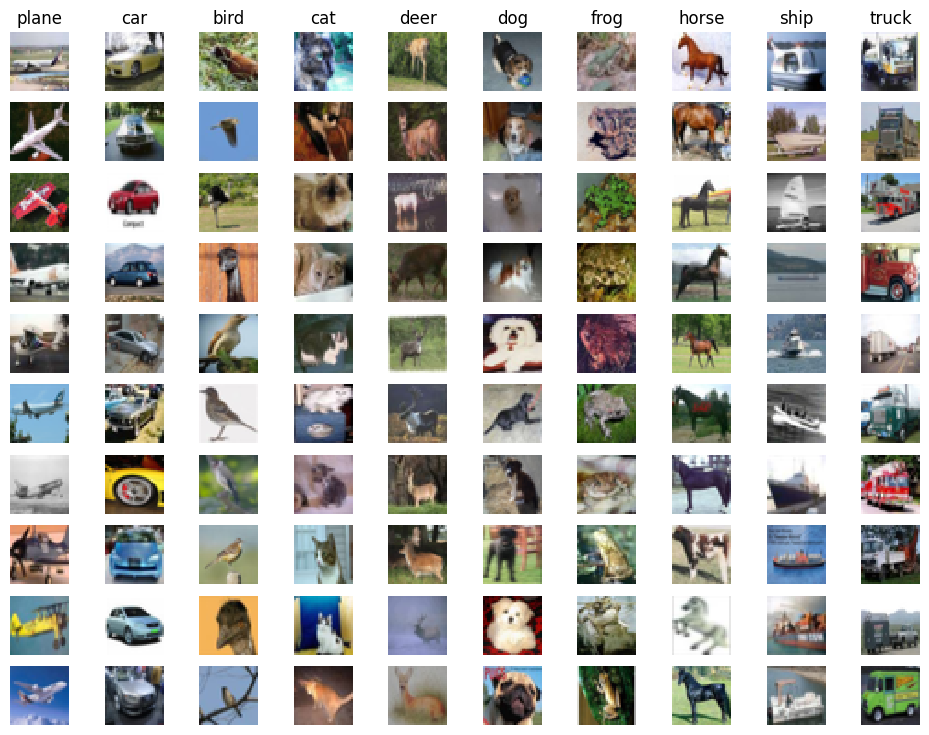

In [4]:
# 可视化数据集中的一些示例.
# 我们展示了每个班的几个训练图像。
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 10      #展示个数可以自定
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

**第 5 块｜固定查询与参考子集**

按题目设置取前 5000 张训练图和前 500 张测试图，以控制距离计算成本。图像和标签使用相同索引切片；后续报告的准确率分母是这 500 张测试图，不能写成完整测试集结果。

前序输入：`X_train` 来自第 3 块，`y_train` 来自第 3 块，`X_test` 来自第 3 块，`y_test` 来自第 3 块。

本块产出的变量接着用于：`X_test` → 第 6 块，`X_train` → 第 6 块，`num_test` → 第 10 块，`num_training` → 第 15 块，`y_test` → 第 10 块。

In [5]:
# 在此练习中对数据进行下取样, 以便提高代码执行效率
num_training = 5000
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

num_test = 500
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

**第 6 块｜把图像展平为行**

把每张 HWC 图像按同一顺序展平为 3072 维向量，得到 (5000,3072) 和 (500,3072) 矩阵。展平只改变形状，不做归一化；欧氏距离因此直接比较像素坐标。

- `np.reshape(X_train, (X_train.shape[0], -1))`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`X_train` 来自第 5 块，`X_test` 来自第 5 块。

本块产出的变量接着用于：`X_test` → 第 8 块，`X_train` → 第 7 块。

In [6]:
# 将图像数据重排成行
X_train = np.reshape(X_train, (X_train.shape[0], -1))  # 保留第一维样本数，把同一张图的 H、W、C 合并成一行，下一步才能与二维权重矩阵相乘。
X_test = np.reshape(X_test, (X_test.shape[0], -1))
print (X_train.shape, X_test.shape)

(5000, 3072) (500, 3072)


**第 7 块｜登记参考样本**

创建 KNearestNeighbor 并调用 train 保存训练样本和标签。kNN 没有梯度更新或拟合权重，其“训练”是记住参考样本；真正的计算开销发生在查询样本与训练样本的距离比较阶段。

本块实际导入：`cs231n.classifiers.KNearestNeighbor`。各模块在本题中的职责见开头的库说明。

前序输入：`X_train` 来自第 6 块，`y_train` 来自第 5 块。

本块产出的变量接着用于：`classifier` → 第 8 块。

In [7]:
from cs231n.classifiers import KNearestNeighbor

# 创建 kNN 分类实例 。
# 记住,训练一个kNN分类器是一个 noop:
# 分类符只记得数据,不再处理
classifier = KNearestNeighbor()
classifier.train(X_train, y_train)

我们现在想用kNN分类器对测试数据进行分类。我们可以把这个过程分成两个步骤:
1. 首先，我们必须计算所有测试样例和所有训练样例之间的距离。
2. 给定这些距离，对于每个测试示例，我们找到k个最近的示例，并让它们为标签投票
让我们从计算所有训练和测试示例之间的距离矩阵开始。例如，如果用**Ntr**代表训练示例和**Nte**代表测试示例，则此阶段将生成一个**Nte x Ntr**矩阵，其中每个元素(i,j)是第i个测试和第j个训练示例之间的距离。
首先,打开`cs231n/classifiers/k_nearest_neighbor.py` ，并实现函数`compute_distances_two_loops`，该函数对所有对(test, train) 示例使用(非常低效的)双循环，并一次计算一个元素的距离矩阵。

**第 8 块｜建立双循环距离基准**

对每个测试样本和每个训练样本执行双重循环，先作 3072 维差向量，再求平方和及平方根。输出距离矩阵 (500,5000)，第 i 行、第 j 列对应测试样本 i 到训练样本 j 的 L2 距离，是后续向量化版本的数值参照。

前序输入：`classifier` 来自第 7 块，`X_test` 来自第 6 块。

本块产出的变量接着用于：`dists` → 第 9 块。

In [8]:
# 打开 cs231n/ 分类器/ k_ near_ nearbor.py 并执行
# compute_distances_two_loops.

# 测试您的执行 :
dists = classifier.compute_distances_two_loops(X_test)
print (dists.shape)

(500, 5000)


**第 9 块｜读距离矩阵的行与列**

将距离矩阵显示为二维图像。每行对应一张测试图，每列对应一张训练图，明暗表示距离大小；亮行通常表示该测试图与多数训练图差异较大。图像不能直接证明分类性能，仍需标签预测和准确率计算。

前序输入：`dists` 来自第 8 块。

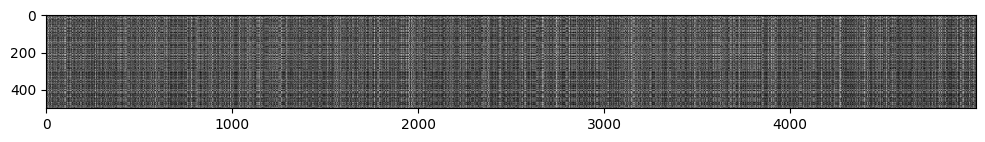

In [9]:
# 我们可以将距离矩阵直观化:每行是一个单一的测试示例和
# 与训练实例的距离
plt.imshow(dists, interpolation='none')
plt.show()

**Inline Question #1:** 注意距离矩阵中的结构化模式，其中一些行或列更亮。(注意，在默认的配色方案中，黑色表示低距离，白色表示高距离。)
- 数据中那些明显明亮的行背后的原因是什么?
- 是什么导致了这些列?

**我的分析：** 距离矩阵的一行对应同一张测试图与所有训练图的距离。较亮的行说明该图在原始像素空间中与多数训练图距离较远，可能与整体亮度、背景、位置或外观有关，不能直接认定它是异常值。较亮的列对应某张训练图与许多测试图都不相似。原始像素距离对平移、背景和光照敏感，这也是 kNN 在本实验中表现有限的原因。

**第 10 块｜用一个邻居投票**

对每行距离排序，选最近的一个训练标签作为预测。把 500 个预测与测试标签逐一比较，用正确数量除以 500 得到 k=1 的准确率；该数值用于理解最近邻规则，不用于后面选择 k。

前序输入：`classifier` 来自第 7 块，`dists` 来自第 8 块，`y_test` 来自第 5 块，`num_test` 来自第 5 块。

In [10]:
# 现在执行函数预测_标签并运行下面的代码:
# 我们使用k=1(这是最近的邻居).
y_test_pred = classifier.predict_labels(dists, k=1)

# 计算和打印正确预测的示例的分数
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print ('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 137 / 500 correct => accuracy: 0.274000


你应该期望看到大约`27%`的准确率。现在让我们尝试一个更大的`k`，比如`k = 5`:

**第 11 块｜把邻域扩大到五个**

保持同一距离矩阵，仅把投票范围改为最近的五个样本。多数票决定类别，平票按实现的最小类别编号规则处理；与 k=1 的差别反映邻域扩大后的平滑作用。

前序输入：`classifier` 来自第 7 块，`dists` 来自第 8 块，`y_test` 来自第 5 块，`num_test` 来自第 5 块。

In [11]:
y_test_pred = classifier.predict_labels(dists, k=5)
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print ('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 139 / 500 correct => accuracy: 0.278000


你应该期望看到比`k = 1`稍微好一点的性能。

**第 12 块｜核对单循环结果**

单循环实现逐个处理测试样本，在训练样本维度向量化差值和求和。输出形状不变，通过与双循环距离矩阵的 Frobenius 范数差检查等价性；初始版本在循环内重复计算了两种范数表达式，计时会包含这一冗余。

前序输入：`classifier` 来自第 7 块，`X_test` 来自第 6 块，`dists` 来自第 8 块。

In [12]:
# 现在通过使用部分矢量化来加速距离矩阵的计算
# 。执行函数计算_距离_1_loop并运行
# 代码如下:
dists_one = classifier.compute_distances_one_loop(X_test)

# 为确保我们矢量执行正确,我们确保
# 同意天真的执行,有许多方法可以决定
# 两个矩阵相似;其中最简单的一个是弗罗贝尼乌斯规范。
# 弗罗贝尼乌斯两个矩阵的规范是方形
# 所有元素差异的平方和根;换句话说,重塑
# 并计算它们之间的欧几利得距离。
difference = np.linalg.norm(dists - dists_one, ord='fro')
print ('Difference was: %f' % (difference, ))
if difference < 0.001:
  print ('Good! The distance matrices are the same')
else:
  print ('Uh-oh! The distance matrices are different')

Difference was: 0.000000
Good! The distance matrices are the same


**第 13 块｜核对矩阵乘法结果**

无循环版本利用 ‖x−y‖²=‖x‖²+‖y‖²−2xᵀy，一次矩阵乘法结合两次广播得到全部距离。继续对照双循环结果检查误差，避免把维度广播错误误认为加速；浮点消去误差可能使理论上的零出现微小负值。

前序输入：`classifier` 来自第 7 块，`X_test` 来自第 6 块，`dists` 来自第 8 块。

In [13]:
# 现在在计算中执行完全矢量化的版本_ 距离_ no_ loops
# 运行代码
dists_two = classifier.compute_distances_no_loops(X_test)

# 请检查archive-date=中的日期值 (帮助) 距离矩阵与我们之前计算的矩阵一致:
difference = np.linalg.norm(dists - dists_two, ord='fro')
print ('Difference was: %f' % (difference, ))
if difference < 0.001:
  print ('Good! The distance matrices are the same')
else:
  print ('Uh-oh! The distance matrices are different')

Difference was: 0.000000


Good! The distance matrices are the same


**第 14 块｜在同一输入上计时**

对相同训练和测试输入分别计时三种距离实现，输出秒数。硬件、BLAS 线程和当前系统负载会影响绝对耗时；数值等价检查通过后，耗时比较才有意义，不能只凭代码行数判断快慢。

此处定义 `time_function(f, *args)`。函数体在调用时执行。

前序输入：`classifier` 来自第 7 块，`X_test` 来自第 6 块。

In [14]:
# 让我们比较一下执行的速度
def time_function(f, *args):
  """调用 f(*args) 一次，返回调用前后时钟读数之差，单位为秒。比较算法时应传入同一批查询样本。"""
  import time
  tic = time.time()
  f(*args)
  toc = time.time()
  return toc - tic

two_loop_time = time_function(classifier.compute_distances_two_loops, X_test)
print ('Two loop version took %f seconds' % two_loop_time)

one_loop_time = time_function(classifier.compute_distances_one_loop, X_test)
print ('One loop version took %f seconds' % one_loop_time)

no_loop_time = time_function(classifier.compute_distances_no_loops, X_test)
print ('No loop version took %f seconds' % no_loop_time)

# 您应当看到以完全矢量执行的速度更快的性能

Two loop version took 9.198189 seconds


One loop version took 56.163366 seconds
No loop version took 0.110274 seconds


### 交叉验证
我们已经实现了k近邻分类器，但是我们随意设置了k = 5的值。现在我们将通过交叉验证来确定这个超参数的最佳值。

**第 15 块｜用训练折选择邻居数**

把 5000 个训练样本均分为十折，每次用九折作参考、一折作验证，对十个候选 k 完成全部十折评估。结果 k_to_accuracies 保存每个 k 的十个验证准确率；测试集完全不进入这一步。方法一对每个 k 重算相同距离，后面的改进会消除这部分重复计算。

- `np.array_split(X_train, num_folds)`：将样本分折，供交叉验证逐折选择训练和验证部分。

本块实际导入：`time.perf_counter`。各模块在本题中的职责见开头的库说明。

前序输入：`X_train` 来自第 6 块，`y_train` 来自第 5 块，`classifier` 来自第 7 块，`num_training` 来自第 5 块。

本块产出的变量接着用于：`X_train_folds` → 第 16 块，`k_choices` → 第 16 块，`k_to_accuracies` → 第 16 块，`num_folds` → 第 16 块，`original_cv_seconds` → 第 16 块。

In [15]:
from time import perf_counter
_original_cv_start = perf_counter()
num_folds = 10
k_choices = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]

X_train_folds = []
y_train_folds = []
X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

# 我们发现的 k 不同值的词典
# 当运行交叉验证时。运行交叉验证后,
# k_to_ 精确度[k] 应该是给出不同长度的 number_ 倍数列表
# 在使用 k 值时发现的精确值。
k_to_accuracies = {}


for k in k_choices:
    accuracies = []
    for j in range(num_folds):
        X_v = X_train_folds[j]
        y_v = y_train_folds[j]
        X_tr = np.vstack(X_train_folds[0:j] + X_train_folds[j+1:])
        y_tr = np.hstack(y_train_folds[0:j] + y_train_folds[j+1:])
        
        classifier.train(X_tr, y_tr)
        dists = classifier.compute_distances_no_loops(X_v)
        y_test_pred = classifier.predict_labels(dists, k)
        num_correct = np.sum(y_test_pred == y_v)
        accuracies.append(float(num_correct) * num_folds / num_training)
        k_to_accuracies[k] = accuracies

# 打印计算出来的速率
for k in sorted(k_to_accuracies):
    for accuracy in k_to_accuracies[k]:
        print ('k = %d, accuracy = %f' % (k, accuracy))
original_cv_seconds = perf_counter() - _original_cv_start


k = 1, accuracy = 0.254000
k = 1, accuracy = 0.268000
k = 1, accuracy = 0.256000
k = 1, accuracy = 0.272000
k = 1, accuracy = 0.270000
k = 1, accuracy = 0.282000
k = 1, accuracy = 0.274000
k = 1, accuracy = 0.282000
k = 1, accuracy = 0.272000
k = 1, accuracy = 0.280000
k = 3, accuracy = 0.232000
k = 3, accuracy = 0.258000
k = 3, accuracy = 0.254000
k = 3, accuracy = 0.246000
k = 3, accuracy = 0.246000
k = 3, accuracy = 0.252000
k = 3, accuracy = 0.278000
k = 3, accuracy = 0.248000
k = 3, accuracy = 0.228000
k = 3, accuracy = 0.268000
k = 5, accuracy = 0.226000
k = 5, accuracy = 0.258000
k = 5, accuracy = 0.284000
k = 5, accuracy = 0.250000
k = 5, accuracy = 0.298000
k = 5, accuracy = 0.270000
k = 5, accuracy = 0.284000
k = 5, accuracy = 0.276000
k = 5, accuracy = 0.252000
k = 5, accuracy = 0.306000
k = 8, accuracy = 0.242000
k = 8, accuracy = 0.268000
k = 8, accuracy = 0.294000
k = 8, accuracy = 0.260000
k = 8, accuracy = 0.286000
k = 8, accuracy = 0.288000
k = 8, accuracy = 0.280000
k

### 方法二：每折只计算一次距离与排序

方法一遍历十个 k 时重复计算了相同的验证—训练距离。这里交换循环顺序：先确定一折，计算一次距离并排序，再从排序结果中截取不同 k 的邻居投票。输入仍是原来的十折数组，输出仍是每个 k 的十折准确率。独立分类器与变量不会改动方法一的状态。

本单元对全部折的结果做精确相等断言，并比较两种完整交叉验证的耗时。收益来自避免重复计算，不表示分类准确率提高；每折计算结束即释放该折距离，未额外保存十份完整矩阵。

**第 16 块：顺着变量读**

此处定义 `cross_validate_cached_method2(X_folds, y_folds, choices)`。函数体在调用时执行。

- `np.argsort(distances, axis=1)`：返回排序位置，用位置查询标签，不直接返回排好序的标签。

- `np.argmax(np.bincount(row[:k]))`：取给定轴上最大值的位置，例如按类别轴取得预测标签。

- `np.bincount(row[:k])`：按整数标签统计票数，把邻居标签转换为类别分布。

本块实际导入：`study_runtime.ROOT`、`json`。各模块在本题中的职责见开头的库说明。

前序输入：`X_train_folds` 来自第 15 块，`y_train_folds` 来自第 15 块，`k_choices` 来自第 15 块，`k_to_accuracies` 来自第 15 块，`original_cv_seconds` 来自第 15 块，`num_folds` 来自第 15 块。

In [16]:
# 方法二保留相同的十折、距离公式和投票规则，仅缓存每折的排序结果。
def cross_validate_cached_method2(X_folds, y_folds, choices):
    from time import perf_counter
    start = perf_counter()
    result = {k: [] for k in choices}
    for fold_index, (X_valid, y_valid) in enumerate(zip(X_folds, y_folds)):
        reference_X = np.vstack([x for j, x in enumerate(X_folds) if j != fold_index])
        reference_y = np.hstack([y for j, y in enumerate(y_folds) if j != fold_index])
        local_classifier = KNearestNeighbor()
        local_classifier.train(reference_X, reference_y)
        distances = local_classifier.compute_distances_no_loops(X_valid)
        # 与原 predict_labels 使用相同的 argsort；相同距离的处理保持一致。
        sorted_indices = np.argsort(distances, axis=1)
        ordered_labels = reference_y[sorted_indices[:, :max(choices)]]
        for k in choices:
            predictions = np.array([np.argmax(np.bincount(row[:k])) for row in ordered_labels])
            result[k].append(float(np.mean(predictions == y_valid)))
    return result, perf_counter() - start

method2_cv, method2_seconds = cross_validate_cached_method2(X_train_folds, y_train_folds, k_choices)
for candidate_k in k_choices:
    np.testing.assert_array_equal(method2_cv[candidate_k], k_to_accuracies[candidate_k])
method2_report = {'original_seconds': original_cv_seconds, 'method2_seconds': method2_seconds,
                  'speedup': original_cv_seconds / method2_seconds, 'fold_results_identical': True,
                  'distance_evaluations_original': len(k_choices) * num_folds,
                  'distance_evaluations_method2': num_folds}
print(method2_report)
from study_runtime import ROOT as _project_root
import json as _json
_report_dir = _project_root / 'outputs' / '001_Knn'
_report_dir.mkdir(parents=True, exist_ok=True)
(_report_dir / 'method2_comparison.json').write_text(_json.dumps(method2_report, indent=2), encoding='utf-8')


{'original_seconds': 20.467528600012884, 'method2_seconds': 2.176749700010987, 'speedup': 9.402793807624999, 'fold_results_identical': True, 'distance_evaluations_original': 100, 'distance_evaluations_method2': 10}


228

**第 17 块｜查看各折分布**

输入每个 k 的十折准确率，绘制各折散点、均值及标准差误差线。误差线表示折间波动，不是置信区间；选取平均验证准确率最好的 k，若均值相同则优先较小的 k。

前序输入：`k_choices` 来自第 15 块，`k_to_accuracies` 来自第 15 块。

本块产出的变量接着用于：`k` → 第 18 块。

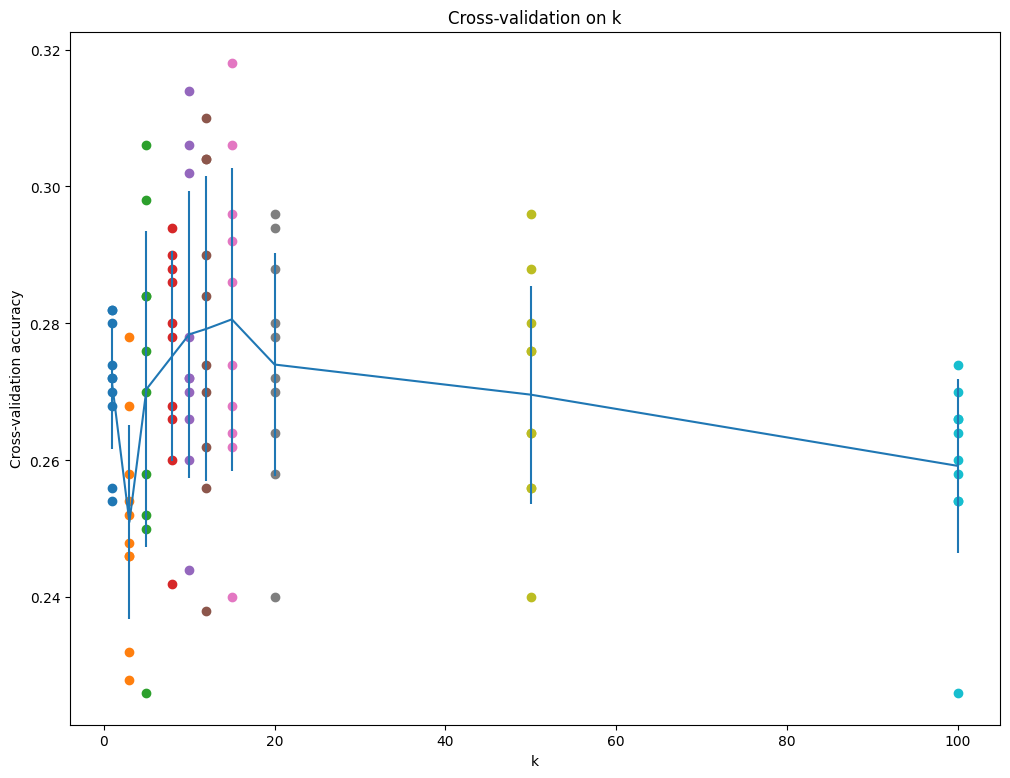

In [17]:
# 绘制原始观测数据
for k in k_choices:
  accuracies = k_to_accuracies[k]
  plt.scatter([k] * len(accuracies), accuracies)

# 以标准偏差对应的错误栏绘制趋势线
accuracies_mean = np.array([np.mean(v) for k,v in sorted(k_to_accuracies.items())])
accuracies_std = np.array([np.std(v) for k,v in sorted(k_to_accuracies.items())])
plt.errorbar(k_choices, accuracies_mean, yerr=accuracies_std)
plt.title('Cross-validation on k')
plt.xlabel('k')
plt.ylabel('Cross-validation accuracy')
plt.show()

**第 18 块｜用选定的 k 预测**

按十折验证均值选定 best_k，重新保存全部 5000 张训练图作为参考，再预测固定的 500 张测试图。输出正确数及测试准确率；即使未达到题目给出的参考水平，也保留真实结果，不能利用测试标签反向挑选 k。

- `classifier.predict(X_test, k=best_k)`：使用已训练的模型计算预测标签。

前序输入：`k_to_accuracies` 来自第 15 块，`k` 来自第 17 块，`X_train` 来自第 6 块，`y_train` 来自第 5 块，`X_test` 来自第 6 块，`y_test` 来自第 5 块，`num_test` 来自第 5 块。

In [18]:
# 根据上述交叉验证结果,为k选择最佳值,
# 使用所有训练数据重新训练分类器,并在测试中测试
# 数据。您应该能够从测试数据中获得28%以上的准确性。
best_k = max(sorted(k_to_accuracies), key=lambda k: np.mean(k_to_accuracies[k]))

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)
y_test_pred = classifier.predict(X_test, k=best_k)

# 计算和显示准确性
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print ('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 136 / 500 correct => accuracy: 0.272000


### 保存本次实验

保存交叉验证结果、最终测试准确率与方法二耗时，不重复保存 CIFAR-10 图像。kNN 没有需要优化的参数，原始训练样本由共享目录复用。

**第 19 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [19]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '001_Knn')


本机实验指标： {'accuracy': 0.272, 'best_k': 15.0}


## 实践补充：问题、检查与方法选择

**实际结果。** 按训练数据十折均值选择 k 后，固定 500 张测试图准确率为 27.2%，没有达到约 28% 的参考水平；不改用测试集挑 k。

**已验证改进。** 方法二缓存每折距离和排序，所有候选 k 的逐折结果与方法一一致，完整交叉验证约加速 9.4 倍。它消除重复计算，不改变距离或分类规则。

**可能问题。** 图像未展平会造成维度错误；距离矩阵大小随样本数乘积增长。若扩展到更大数据，应分块计算并验证投票和平票规则一致，不能简单截断训练样本后仍称为同一实验。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。